In [ ]:
# ==========================================================
# IMPORTS
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split

from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    classification_report,

    confusion_matrix,

    ConfusionMatrixDisplay

)

In [ ]:
# ==========================================================
# LOAD DATASET
# ==========================================================

dataset = pd.read_csv(

    "/content/drive/MyDrive/Exoplanet_Dataset/11_Training_Dataset_V2/Training_Dataset_V2.csv"

)

print("="*60)
print("TRAINING DATASET V2")
print("="*60)

print()

print("Rows :", len(dataset))
print("Columns :", len(dataset.columns))

display(dataset.head())

TRAINING DATASET V2

Rows : 1172
Columns : 31


,TIC_ID,Label,Number_of_Sectors,Best_Sector,period_days,duration_days,epoch_days,bls_depth,bls_power,peak_sigma,...,secondary_depth,secondary_snr,duty_cycle,oot_rms,transit_rms,shape_rmse,transit_skewness,transit_kurtosis,transit_mad,transit_iqr
0,100100829,EB,3,69,0.942324,0.075,3182.749443,0.007126,928.753290,13.017379,...,584.814466,0.096849,0.103831,0.005761,0.006450,0.009890,-0.193433,0.170547,0.004188,0.008398
1,1001477809,False Positive,4,48,7.656943,0.168,2616.800708,0.001701,30.981110,5.724197,...,0.000000,0.000000,0.023072,0.008116,0.008817,0.009999,0.017202,1.211668,0.004985,0.009937
2,100389539,Planet,2,88,4.280297,0.114,3693.099793,0.005744,2436.410323,14.040970,...,253.630337,0.139124,0.029782,0.001933,0.002059,0.002368,0.114596,-0.136550,0.001398,0.002800
3,10048801,EB,2,47,3.700200,0.141,2583.045512,0.000936,1420.646948,9.640867,...,10.394129,0.017860,0.048227,0.000564,0.000582,0.000704,0.317949,0.752866,0.000374,0.000746
4,100589632,False Positive,1,87,3.946741,0.066,3665.759898,0.001609,75.715224,10.109563,...,96.806526,0.050277,0.023197,0.001926,0.001849,0.002397,-0.084457,-0.230016,0.001135,0.002265


In [ ]:
# ==========================================================
# FEATURE SELECTION
# ==========================================================

FEATURES = [

    # Transit Detection

    "period_days",

    "duration_days",

    "bls_depth",

    "bls_power",

    "peak_sigma",

    # Transit Geometry

    "depth_ppm",

    "T_tot_hours",

    "T_in_hours",

    "ingress_phase",

    "red_chi2",

    "rms_resid",

    # Physics V1

    "ingress_fraction",

    "flat_bottom_fraction",

    "transit_snr",

    "odd_even_ratio",

    "secondary_depth",

    "secondary_snr",

    "duty_cycle",

    # Physics V2

    "oot_rms",

    "transit_rms",

    "shape_rmse",

    "transit_skewness",

    "transit_kurtosis",

    "transit_mad",

    "transit_iqr"

]

TARGET = "Label"

print()

print("Number of Features :", len(FEATURES))


Number of Features : 25


In [ ]:
# ==========================================================
# PREPARE DATA
# ==========================================================

X = dataset[FEATURES].copy()

y = dataset[TARGET].copy()

imputer = SimpleImputer(

    strategy="median"

)

X = pd.DataFrame(

    imputer.fit_transform(X),

    columns=FEATURES

)

print("=" * 60)
print("MISSING VALUES AFTER IMPUTATION")
print("=" * 60)

print()

print(X.isna().sum().sum())

MISSING VALUES AFTER IMPUTATION

0


In [ ]:
# ==========================================================
# LABEL ENCODING
# ==========================================================

label_mapping = {

    "Planet": 0,

    "EB": 1,

    "False Positive": 2

}

y = y.map(label_mapping)

print("=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

print()

print(y.value_counts())

CLASS DISTRIBUTION

Label
1    400
0    399
2    373
Name: count, dtype: int64


In [ ]:
# ==========================================================
# TRAIN / TEST SPLIT
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

print("=" * 60)
print("DATA SPLIT")
print("=" * 60)

print()

print("Training :", len(X_train))

print("Testing  :", len(X_test))

DATA SPLIT

Training : 937
Testing  : 235


In [ ]:
# ==========================================================
# TRAIN XGBOOST
# ==========================================================

model = XGBClassifier(

    n_estimators=300,

    max_depth=6,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="multi:softprob",

    eval_metric="mlogloss",

    random_state=42

)

model.fit(

    X_train,

    y_train

)

print()

print("Training Complete!")


Training Complete!


In [ ]:
# ==========================================================
# PREDICTIONS
# ==========================================================

train_predictions = model.predict(

    X_train

)

test_predictions = model.predict(

    X_test

)

In [ ]:
# ==========================================================
# TRAINING PERFORMANCE
# ==========================================================

print("=" * 60)
print("TRAINING PERFORMANCE")
print("=" * 60)

print()

print(

    "Accuracy :", accuracy_score(y_train, train_predictions)

)

print(

    "Precision:",

    precision_score(

        y_train,

        train_predictions,

        average="weighted"

    )

)

print(

    "Recall   :",

    recall_score(

        y_train,

        train_predictions,

        average="weighted"

    )

)

print(

    "F1 Score :",

    f1_score(

        y_train,

        train_predictions,

        average="weighted"

    )

)

print()

print("=" * 60)
print("TEST PERFORMANCE")
print("=" * 60)

print()

print(

    "Accuracy :", accuracy_score(y_test, test_predictions)

)

print(

    "Precision:",

    precision_score(

        y_test,

        test_predictions,

        average="weighted"

    )

)

print(

    "Recall   :",

    recall_score(

        y_test,

        test_predictions,

        average="weighted"

    )

)

print(

    "F1 Score :",

    f1_score(

        y_test,

        test_predictions,

        average="weighted"

    )

)

TRAINING PERFORMANCE

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

TEST PERFORMANCE

Accuracy : 0.7957446808510639
Precision: 0.7949376949633293
Recall   : 0.7957446808510639
F1 Score : 0.7951440707629095


<Figure size 600x600 with 0 Axes>

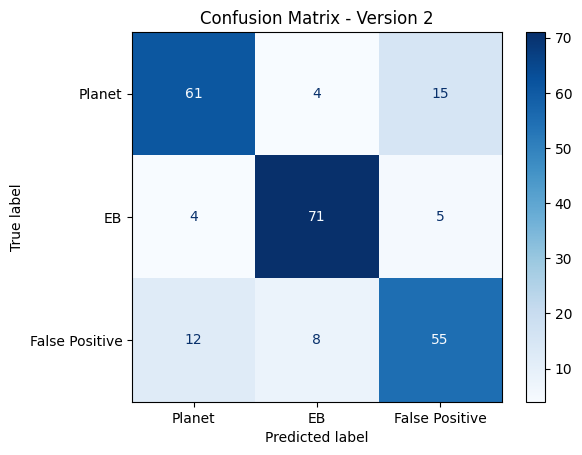

In [ ]:
cm = confusion_matrix(

    y_test,

    test_predictions

)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=[

        "Planet",

        "EB",

        "False Positive"

    ]

)

plt.figure(figsize=(6,6))

disp.plot(

    cmap="Blues",

    values_format="d"

)

plt.title(

    "Confusion Matrix - Version 2"

)

plt.show()

In [ ]:
print(

    classification_report(

        y_test,

        test_predictions,

        target_names=[

            "Planet",

            "EB",

            "False Positive"

        ]

    )

)

                precision    recall  f1-score   support

        Planet       0.79      0.76      0.78        80
            EB       0.86      0.89      0.87        80
False Positive       0.73      0.73      0.73        75

      accuracy                           0.80       235
     macro avg       0.79      0.79      0.79       235
  weighted avg       0.79      0.80      0.80       235



                 Feature  Importance
3              bls_power    0.144852
7             T_in_hours    0.082552
5              depth_ppm    0.079164
2              bls_depth    0.049142
8          ingress_phase    0.048131
16         secondary_snr    0.047645
13           transit_snr    0.039653
11      ingress_fraction    0.035483
22      transit_kurtosis    0.035289
9               red_chi2    0.034131
0            period_days    0.032583
18               oot_rms    0.031401
19           transit_rms    0.029990
17            duty_cycle    0.029799
4             peak_sigma    0.029511
6            T_tot_hours    0.027975
21      transit_skewness    0.027597
12  flat_bottom_fraction    0.027039
15       secondary_depth    0.026897
20            shape_rmse    0.026351
1          duration_days    0.026212
23           transit_mad    0.024973
10             rms_resid    0.023082
14        odd_even_ratio    0.020914
24           transit_iqr    0.019632


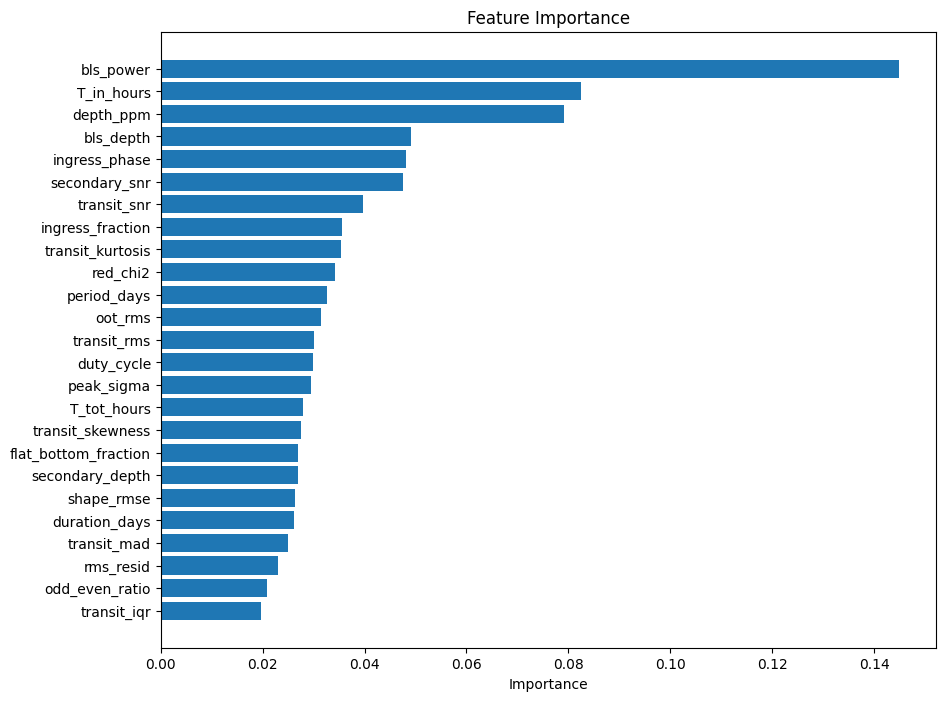

In [ ]:
importance = pd.DataFrame({

    "Feature": FEATURES,

    "Importance": model.feature_importances_

})

importance = importance.sort_values(

    by="Importance",

    ascending=False

)

print(importance)

plt.figure(figsize=(10,8))

plt.barh(

    importance["Feature"],

    importance["Importance"]

)

plt.gca().invert_yaxis()

plt.title("Feature Importance")

plt.xlabel("Importance")

plt.show()

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from scipy.stats import uniform

In [ ]:
# ==========================================================
# VERSION 3 - RANDOMIZED HYPERPARAMETER SEARCH
# ==========================================================

xgb = XGBClassifier(

    objective="multi:softprob",

    eval_metric="mlogloss",

    random_state=42

)

param_grid = {

    "n_estimators": randint(100, 301),

    "max_depth": randint(3, 7),

    "learning_rate": uniform(0.03, 0.08),

    "min_child_weight": randint(1, 6),

    "gamma": uniform(0, 2),

    "subsample": uniform(0.7, 0.3),

    "colsample_bytree": uniform(0.7, 0.3),

    "reg_alpha": uniform(0, 1),

    "reg_lambda": uniform(1, 3)

}

search = RandomizedSearchCV(

    estimator=xgb,

    param_distributions=param_grid,

    n_iter=30,

    scoring="f1_weighted",

    cv=5,

    verbose=2,

    random_state=42,

    n_jobs=-1

)

search.fit(

    X_train,

    y_train

)

model = search.best_estimator_

print()

print("="*60)

print("BEST PARAMETERS")

print("="*60)

print()

print(search.best_params_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

BEST PARAMETERS

{'colsample_bytree': np.float64(0.7536468127663986), 'gamma': np.float64(0.7329375691657198), 'learning_rate': np.float64(0.08953364184452497), 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 227, 'reg_alpha': np.float64(0.5683086033354716), 'reg_lambda': np.float64(1.2810243034842774), 'subsample': np.float64(0.81031474091783)}


In [ ]:
train_predictions = model.predict(X_train)

test_predictions = model.predict(X_test)

In [ ]:
# ==========================================================
# VERSION 3 PERFORMANCE
# ==========================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# -----------------------------
# Training Predictions
# -----------------------------

train_predictions = model.predict(X_train)

# -----------------------------
# Testing Predictions
# -----------------------------

test_predictions = model.predict(X_test)

# -----------------------------
# Training Metrics
# -----------------------------

print("="*60)
print("TRAINING PERFORMANCE")
print("="*60)

print()

print(f"Accuracy : {accuracy_score(y_train, train_predictions):.4f}")

print(f"Precision: {precision_score(y_train, train_predictions, average='weighted'):.4f}")

print(f"Recall   : {recall_score(y_train, train_predictions, average='weighted'):.4f}")

print(f"F1 Score : {f1_score(y_train, train_predictions, average='weighted'):.4f}")

print()

# -----------------------------
# Testing Metrics
# -----------------------------

print("="*60)
print("TEST PERFORMANCE")
print("="*60)

print()

print(f"Accuracy : {accuracy_score(y_test, test_predictions):.4f}")

print(f"Precision: {precision_score(y_test, test_predictions, average='weighted'):.4f}")

print(f"Recall   : {recall_score(y_test, test_predictions, average='weighted'):.4f}")

print(f"F1 Score : {f1_score(y_test, test_predictions, average='weighted'):.4f}")

TRAINING PERFORMANCE

Accuracy : 0.9648
Precision: 0.9652
Recall   : 0.9648
F1 Score : 0.9649

TEST PERFORMANCE

Accuracy : 0.7872
Precision: 0.7864
Recall   : 0.7872
F1 Score : 0.7863


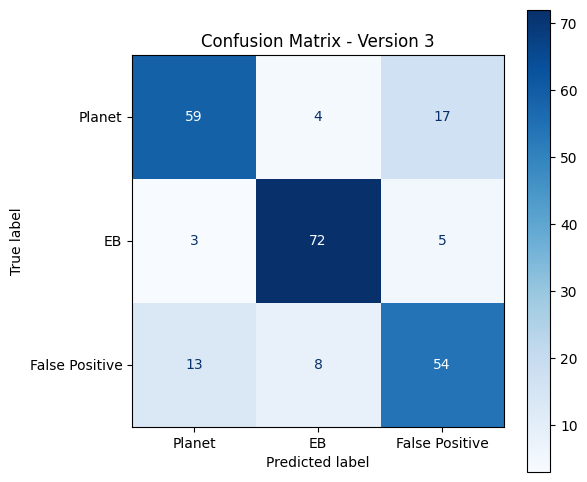


CLASSIFICATION REPORT

                precision    recall  f1-score   support

        Planet       0.79      0.74      0.76        80
            EB       0.86      0.90      0.88        80
False Positive       0.71      0.72      0.72        75

      accuracy                           0.79       235
     macro avg       0.78      0.79      0.78       235
  weighted avg       0.79      0.79      0.79       235



In [ ]:
# ==========================================================
# CONFUSION MATRIX
# ==========================================================

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import matplotlib.pyplot as plt

cm = confusion_matrix(

    y_test,

    test_predictions

)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=[

        "Planet",

        "EB",

        "False Positive"

    ]

)

fig, ax = plt.subplots(figsize=(6,6))

disp.plot(

    cmap="Blues",

    values_format="d",

    ax=ax

)

plt.title("Confusion Matrix - Version 3")

plt.show()

print()

print("="*60)
print("CLASSIFICATION REPORT")
print("="*60)

print()

print(

    classification_report(

        y_test,

        test_predictions,

        target_names=[

            "Planet",

            "EB",

            "False Positive"

        ]

    )

)

In [ ]:
# ==========================================================
# VERSION 3 FEATURE SET
# ==========================================================

FEATURES = [

    # Transit Detection
    "period_days",
    "duration_days",
    "bls_depth",
    "bls_power",
    "peak_sigma",

    # Transit Geometry
    "depth_ppm",
    "T_tot_hours",
    "T_in_hours",
    "ingress_phase",
    "red_chi2",

    # Physics V1
    "ingress_fraction",
    "flat_bottom_fraction",
    "transit_snr",
    "secondary_depth",
    "secondary_snr",
    "duty_cycle",

    # Physics V2
    "oot_rms",
    "transit_rms",
    "shape_rmse",
    "transit_skewness",
    "transit_kurtosis"

]

TARGET = "Label"

print("Number of Features :", len(FEATURES))

Number of Features : 21


In [ ]:
# ==========================================================
# PREPARE DATA
# ==========================================================

X = dataset[FEATURES].copy()

y = dataset[TARGET].copy()

imputer = SimpleImputer(

    strategy="median"

)

X = pd.DataFrame(

    imputer.fit_transform(X),

    columns=FEATURES

)

label_mapping = {

    "Planet":0,

    "EB":1,

    "False Positive":2

}

y = y.map(label_mapping)

In [ ]:
# ==========================================================
# TRAIN TEST SPLIT
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

print("Train :",len(X_train))

print("Test  :",len(X_test))

Train : 937
Test  : 235


In [ ]:
# ==========================================================
# VALIDATION SPLIT
# ==========================================================

X_train2, X_valid, y_train2, y_valid = train_test_split(

    X_train,

    y_train,

    test_size=0.20,

    random_state=42,

    stratify=y_train

)

print("Train      :",len(X_train2))

print("Validation :",len(X_valid))

Train      : 749
Validation : 188


In [ ]:
# ==========================================================
# VERSION 3 MODEL
# ==========================================================

model = XGBClassifier(

    n_estimators=500,

    learning_rate=0.05,

    max_depth=4,

    min_child_weight=5,

    gamma=1,

    subsample=0.8,

    colsample_bytree=0.8,

    reg_alpha=0.2,

    reg_lambda=2,

    objective="multi:softprob",

    eval_metric="mlogloss",

    random_state=42

)

model.fit(

    X_train2,

    y_train2,

    eval_set=[

        (X_valid,y_valid)

    ],

    verbose=False

)

print()

print("="*60)

print("VERSION 3 TRAINED")

print("="*60)


VERSION 3 TRAINED


In [ ]:
# ==========================================================
# PREDICTIONS
# ==========================================================

train_predictions = model.predict(

    X_train

)

test_predictions = model.predict(

    X_test

)

In [ ]:
# ==========================================================
# PERFORMANCE
# ==========================================================

print("="*60)
print("TRAINING PERFORMANCE")
print("="*60)

print()

print("Accuracy :",accuracy_score(y_train,train_predictions))
print("Precision:",precision_score(y_train,train_predictions,average="weighted"))
print("Recall   :",recall_score(y_train,train_predictions,average="weighted"))
print("F1 Score :",f1_score(y_train,train_predictions,average="weighted"))

print()

print("="*60)
print("TEST PERFORMANCE")
print("="*60)

print()

print("Accuracy :",accuracy_score(y_test,test_predictions))
print("Precision:",precision_score(y_test,test_predictions,average="weighted"))
print("Recall   :",recall_score(y_test,test_predictions,average="weighted"))
print("F1 Score :",f1_score(y_test,test_predictions,average="weighted"))

TRAINING PERFORMANCE

Accuracy : 0.9135538954108858
Precision: 0.914396970525451
Recall   : 0.9135538954108858
F1 Score : 0.9138542239781162

TEST PERFORMANCE

Accuracy : 0.7574468085106383
Precision: 0.7536893644528188
Recall   : 0.7574468085106383
F1 Score : 0.753682052674214


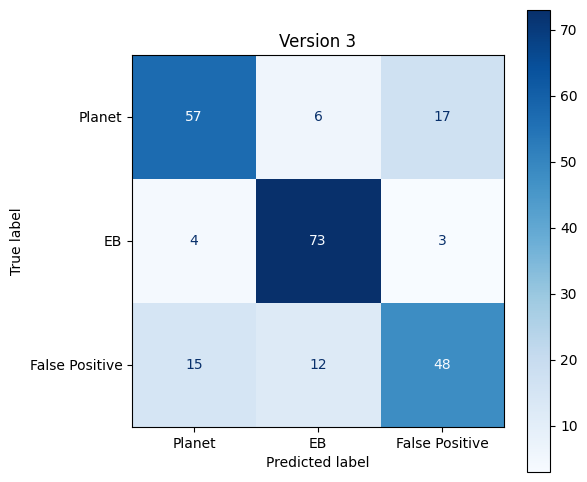


                precision    recall  f1-score   support

        Planet       0.75      0.71      0.73        80
            EB       0.80      0.91      0.85        80
False Positive       0.71      0.64      0.67        75

      accuracy                           0.76       235
     macro avg       0.75      0.76      0.75       235
  weighted avg       0.75      0.76      0.75       235



In [ ]:
# ==========================================================
# CONFUSION MATRIX
# ==========================================================

cm = confusion_matrix(

    y_test,

    test_predictions

)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=[

        "Planet",

        "EB",

        "False Positive"

    ]

)

fig,ax=plt.subplots(figsize=(6,6))

disp.plot(

    cmap="Blues",

    values_format="d",

    ax=ax

)

plt.title("Version 3")

plt.show()

print()

print(classification_report(

    y_test,

    test_predictions,

    target_names=[

        "Planet",

        "EB",

        "False Positive"

    ]

))

,Feature,Importance
5,depth_ppm,0.140468
3,bls_power,0.124495
2,bls_depth,0.097925
7,T_in_hours,0.071706
10,ingress_fraction,0.050386
9,red_chi2,0.046805
8,ingress_phase,0.040986
0,period_days,0.040815
11,flat_bottom_fraction,0.039873
12,transit_snr,0.036773


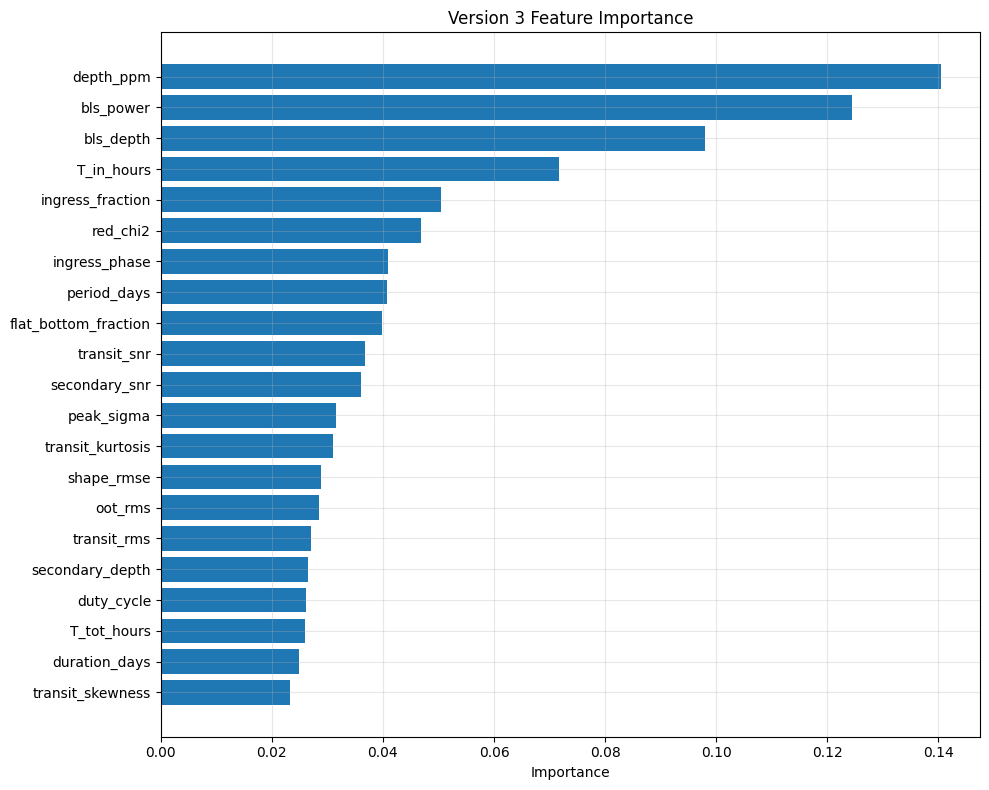

In [ ]:
# ==========================================================
# FEATURE IMPORTANCE
# ==========================================================

importance = pd.DataFrame({

    "Feature":FEATURES,

    "Importance":model.feature_importances_

})

importance = importance.sort_values(

    by="Importance",

    ascending=False

)

display(importance)

plt.figure(figsize=(10,8))

plt.barh(

    importance["Feature"],

    importance["Importance"]

)

plt.gca().invert_yaxis()

plt.xlabel("Importance")

plt.title("Version 3 Feature Importance")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate

In [ ]:
# ==========================================================
# FINAL MODEL (VERSION 2)
# ==========================================================

model = XGBClassifier(

    n_estimators=300,

    max_depth=6,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="multi:softprob",

    eval_metric="mlogloss",

    random_state=42

)

In [ ]:
# ==========================================================
# STRATIFIED 5-FOLD CROSS VALIDATION
# ==========================================================

cv = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42

)

scores = cross_validate(

    model,

    X,

    y,

    cv=cv,

    scoring=[

        "accuracy",

        "precision_weighted",

        "recall_weighted",

        "f1_weighted"

    ],

    return_train_score=True,

    n_jobs=-1

)

In [ ]:
# ==========================================================
# CROSS VALIDATION RESULTS
# ==========================================================

print("="*70)
print("5-FOLD STRATIFIED CROSS VALIDATION")
print("="*70)

print()

print("Training Accuracy")

print(

    f"{scores['train_accuracy'].mean():.4f}"

    " ± "

    f"{scores['train_accuracy'].std():.4f}"

)

print()

print("Validation Accuracy")

print(

    f"{scores['test_accuracy'].mean():.4f}"

    " ± "

    f"{scores['test_accuracy'].std():.4f}"

)

print()

print("Validation Precision")

print(

    f"{scores['test_precision_weighted'].mean():.4f}"

    " ± "

    f"{scores['test_precision_weighted'].std():.4f}"

)

print()

print("Validation Recall")

print(

    f"{scores['test_recall_weighted'].mean():.4f}"

    " ± "

    f"{scores['test_recall_weighted'].std():.4f}"

)

print()

print("Validation F1")

print(

    f"{scores['test_f1_weighted'].mean():.4f}"

    " ± "

    f"{scores['test_f1_weighted'].std():.4f}"

)

5-FOLD STRATIFIED CROSS VALIDATION

Training Accuracy
1.0000 ± 0.0000

Validation Accuracy
0.7892 ± 0.0115

Validation Precision
0.7931 ± 0.0100

Validation Recall
0.7892 ± 0.0115

Validation F1
0.7903 ± 0.0105


In [ ]:
# ==========================================================
# INDIVIDUAL FOLD RESULTS
# ==========================================================

results = pd.DataFrame({

    "Fold":[1,2,3,4,5],

    "Accuracy":scores["test_accuracy"],

    "Precision":scores["test_precision_weighted"],

    "Recall":scores["test_recall_weighted"],

    "F1":scores["test_f1_weighted"]

})

display(results)

,Fold,Accuracy,Precision,Recall,F1
0,1,0.804255,0.804059,0.804255,0.803892
1,2,0.787234,0.800665,0.787234,0.790718
2,3,0.769231,0.775368,0.769231,0.771664
3,4,0.794872,0.794456,0.794872,0.794510
4,5,0.790598,0.790878,0.790598,0.790718


In [ ]:
# ==========================================================
# FINAL MODEL
# ==========================================================

model.fit(

    X,

    y

)

print()

print("="*60)

print("FINAL MODEL TRAINED ON ENTIRE DATASET")

print("="*60)


FINAL MODEL TRAINED ON ENTIRE DATASET


In [ ]:
import joblib

joblib.dump(

    model,

    "/content/drive/MyDrive/Exoplanet_Dataset/final_xgboost_model.pkl"

)

print("Model Saved Successfully")

Model Saved Successfully


In [ ]:
from pathlib import Path

# -------------------------------
# Folder Paths
# -------------------------------

preprocessed_folder = Path("/content/drive/MyDrive/Exoplanet_Dataset/05_Preprocessed_LightCurves")
lightcurve_folder   = Path("/content/drive/MyDrive/Exoplanet_Dataset/03_Light_Curves")

# -------------------------------
# Count CSV Files
# -------------------------------

preprocessed_csv = list(preprocessed_folder.glob("*.csv"))
lightcurve_csv   = list(lightcurve_folder.glob("*.csv"))

print("=" * 60)
print("CSV FILE COUNT")
print("=" * 60)

print(f"Preprocessed Light Curves : {len(preprocessed_csv)} CSV files")
print(f"Raw Light Curves          : {len(lightcurve_csv)} CSV files")

CSV FILE COUNT
Preprocessed Light Curves : 1172 CSV files
Raw Light Curves          : 0 CSV files


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/Exoplanet_Dataset/03_Light_Curves")

fits_files = list(root.rglob("*.fits"))

# Parent folder before MAST_Download is the star folder
star_folders = {f.parents[1].name for f in fits_files}

print("=" * 60)
print("LIGHT CURVE DATASET SUMMARY")
print("=" * 60)
print(f"Unique Star Folders : {len(star_folders)}")
print(f"Total FITS Files    : {len(fits_files)}")
print(f"Average FITS/Star   : {len(fits_files)/len(star_folders):.2f}")

KeyboardInterrupt: 

In [ ]:
import os
from pathlib import Path
from tqdm.auto import tqdm

root = Path("/content/drive/MyDrive/Exoplanet_Dataset/03_Light_Curves")

tic_folders = sorted(root.glob("TIC_*"))

fits_count = 0

print("=" * 60)
print("COUNTING DOWNLOADED TESS FITS FILES")
print("=" * 60)

for tic in tqdm(tic_folders, total=len(tic_folders), desc="Processing Stars"):

    fits_count += len(list(tic.rglob("*.fits")))

print("\n" + "=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

print(f"TIC Targets      : {len(tic_folders):,}")
print(f"Total FITS Files : {fits_count:,}")
print(f"Average FITS/TIC : {fits_count/len(tic_folders):.2f}")

COUNTING DOWNLOADED TESS FITS FILES


Processing Stars:   0%|          | 0/1200 [00:00<?, ?it/s]


DATASET SUMMARY
TIC Targets      : 1,200
Total FITS Files : 8,610
Average FITS/TIC : 7.17


In [ ]:
import pandas as pd

# ==========================================================
# LOAD TRAINING DATASET V2
# ==========================================================

input_file = "/content/drive/MyDrive/Exoplanet_Dataset/11_Training_Dataset_V2/Training_Dataset_V2.csv"

df = pd.read_csv(input_file)

# ==========================================================
# REMOVE COLUMNS NOT USED BY THE TRAINED MODEL
# ==========================================================

columns_to_remove = [

    "Number_of_Sectors",
    "Best_Sector",
    "epoch_days",
    "duration_phase",
    "rms_resid",
    "odd_even_ratio",
    "transit_mad",
    "transit_iqr"

]

df_v1 = df.drop(columns=columns_to_remove)

# ==========================================================
# SAVE AS A NEW FILE (ORIGINAL REMAINS UNCHANGED)
# ==========================================================

output_file = "/content/drive/MyDrive/Exoplanet_Dataset/11_Training_Dataset_V2/Training_Dataset_ModelCompatible.csv"

df_v1.to_csv(output_file, index=False)

print("✅ Saved:", output_file)
print("Shape:", df_v1.shape)

✅ Saved: /content/drive/MyDrive/Exoplanet_Dataset/11_Training_Dataset_V2/Training_Dataset_ModelCompatible.csv
Shape: (1172, 23)


In [ ]:
import joblib
import pandas as pd

# Load model
model = joblib.load(
    "/content/drive/MyDrive/Exoplanet_Dataset/final_xgboost_model.pkl"
)

# Load compatible dataset
df = pd.read_csv(
    "/content/drive/MyDrive/Exoplanet_Dataset/11_Training_Dataset_V2/Training_Dataset_ModelCompatible.csv"
)

# Pick random planet
planet = df[df["Label"] == "Planet"].sample(1, random_state=42)

# Features expected by model
X_sample = planet[model.feature_names_in_]

# Predict
prediction = model.predict(X_sample)[0]
probability = model.predict_proba(X_sample).max()

print("Prediction :", prediction)
print("Confidence :", probability)

Prediction : 0
Confidence : 0.8713007


In [ ]:
print("Classes in dataset:")
print(sorted(df["Label"].unique()))

print("\nEncoded classes:")
encoder = LabelEncoder()
encoder.fit(df["Label"])
print(encoder.classes_)

X = df[model.feature_names_in_].astype(float)

pred = model.predict(X)

print("\nUnique model outputs:")
print(pd.Series(pred).value_counts())

Classes in dataset:
['EB', 'False Positive', 'Planet']

Encoded classes:
['EB' 'False Positive' 'Planet']

Unique model outputs:
1    403
0    396
2    373
Name: count, dtype: int64


In [ ]:
mapping = dict(zip(range(len(encoder.classes_)), encoder.classes_))
print(mapping)

{0: 'EB', 1: 'False Positive', 2: 'Planet'}


In [ ]:
X = df[model.feature_names_in_].astype(float)

pred = model.predict(X)

pred = encoder.inverse_transform(pred)

print(pd.crosstab(df["Label"], pred))

col_0            EB  False Positive  Planet
Label                                      
EB                0             400       0
False Positive    0               0     373
Planet          396               3       0


In [ ]:
# ==========================================================
# PICK RANDOM PLANET
# ==========================================================

sample = df[df["Label"] == "Planet"].sample(1, random_state=42)

X_sample = sample[model.feature_names_in_].astype(float)

prediction = model.predict(X_sample)[0]
probability = model.predict_proba(X_sample).max()

mapping = {
    0: "Planet",
    1: "EB",
    2: "False Positive"
}

predicted_class = mapping[prediction]

sample = sample.iloc[0]

print("="*72)
print("                 AI EXOPLANET DETECTION REPORT")
print("="*72)

print(f"TIC ID                 : {sample['TIC_ID']}")
print(f"Predicted Class        : {predicted_class}")
print(f"Prediction Confidence  : {probability*100:.2f}%")

print("\nTRANSIT PARAMETERS")
print("-"*72)
print(f"Orbital Period         : {sample['period_days']:.4f} days")
print(f"Transit Depth          : {sample['depth_ppm']:.0f} ppm")
print(f"Transit Duration       : {sample['T_tot_hours']:.2f} hours")
print(f"Ingress Duration       : {sample['T_in_hours']:.2f} hours")

print("\nPHYSICS FEATURES")
print("-"*72)
print(f"Transit SNR            : {sample['transit_snr']:.2f}")
print(f"Ingress Fraction       : {sample['ingress_fraction']:.3f}")
print(f"Flat Bottom Fraction   : {sample['flat_bottom_fraction']:.3f}")
print(f"Secondary Depth        : {sample['secondary_depth']:.0f} ppm")
print(f"Secondary SNR          : {sample['secondary_snr']:.2f}")

print("\nBLS DETECTION")
print("-"*72)
print(f"BLS Power              : {sample['bls_power']:.2f}")
print(f"Peak Significance      : {sample['peak_sigma']:.2f}")

print("\nMODEL DECISION")
print("-"*72)
print("Candidate Status       : ✓ PLANET CANDIDATE")
print("Follow-up Priority     : HIGH")

print("="*72)

                 AI EXOPLANET DETECTION REPORT
TIC ID                 : 273874849
Predicted Class        : Planet
Prediction Confidence  : 87.13%

TRANSIT PARAMETERS
------------------------------------------------------------------------
Orbital Period         : 2.0445 days
Transit Depth          : 52059 ppm
Transit Duration       : 4.60 hours
Ingress Duration       : 1.69 hours

PHYSICS FEATURES
------------------------------------------------------------------------
Transit SNR            : 2.60
Ingress Fraction       : 0.368
Flat Bottom Fraction   : 0.265
Secondary Depth        : 7821 ppm
Secondary SNR          : 0.56

BLS DETECTION
------------------------------------------------------------------------
BLS Power              : 7330.95
Peak Significance      : 12.98

MODEL DECISION
------------------------------------------------------------------------
Candidate Status       : ✓ PLANET CANDIDATE
Follow-up Priority     : HIGH


In [ ]:
# ==========================================================
# PICK RANDOM EB
# ==========================================================

sample = df[df["Label"] == "EB"].sample(1, random_state=42)

X_sample = sample[model.feature_names_in_].astype(float)

prediction = model.predict(X_sample)[0]
probability = model.predict_proba(X_sample).max()

CLASS_MAPPING = {
    0: "Planet",
    1: "EB",
    2: "False Positive"
}

predicted_class = CLASS_MAPPING[prediction]

sample = sample.iloc[0]

# ==========================================================
# REPORT
# ==========================================================

print("="*72)
print("                 AI CANDIDATE EVALUATION REPORT")
print("="*72)

print(f"TIC ID                 : {sample['TIC_ID']}")
print(f"Predicted Class        : {predicted_class}")
print(f"Prediction Confidence  : {probability*100:.2f}%")

print("\nTRANSIT PARAMETERS")
print("-"*72)
print(f"Orbital Period         : {sample['period_days']:.4f} days")
print(f"Transit Depth          : {sample['depth_ppm']:.0f} ppm")
print(f"Transit Duration       : {sample['T_tot_hours']:.2f} hours")
print(f"Ingress Duration       : {sample['T_in_hours']:.2f} hours")

print("\nPHYSICS FEATURES")
print("-"*72)
print(f"Transit SNR            : {sample['transit_snr']:.2f}")
print(f"Ingress Fraction       : {sample['ingress_fraction']:.3f}")
print(f"Flat Bottom Fraction   : {sample['flat_bottom_fraction']:.3f}")
print(f"Secondary Depth        : {sample['secondary_depth']:.0f} ppm")
print(f"Secondary SNR          : {sample['secondary_snr']:.2f}")

print("\nBLS DETECTION")
print("-"*72)
print(f"BLS Power              : {sample['bls_power']:.2f}")
print(f"Peak Significance      : {sample['peak_sigma']:.2f}")

print("\nMODEL DECISION")
print("-"*72)

print("Candidate Status       : ✗ ECLIPSING BINARY")
print("PARAS-2 Follow-up      : LOW PRIORITY")

print("="*72)

                 AI CANDIDATE EVALUATION REPORT
TIC ID                 : 293480903
Predicted Class        : EB
Prediction Confidence  : 98.94%

TRANSIT PARAMETERS
------------------------------------------------------------------------
Orbital Period         : 7.5699 days
Transit Depth          : 26449 ppm
Transit Duration       : 2.63 hours
Ingress Duration       : 0.94 hours

PHYSICS FEATURES
------------------------------------------------------------------------
Transit SNR            : 9.89
Ingress Fraction       : 0.356
Flat Bottom Fraction   : 0.288
Secondary Depth        : 5620 ppm
Secondary SNR          : 2.97

BLS DETECTION
------------------------------------------------------------------------
BLS Power              : 32464.14
Peak Significance      : 9.80

MODEL DECISION
------------------------------------------------------------------------
Candidate Status       : ✗ ECLIPSING BINARY
PARAS-2 Follow-up      : LOW PRIORITY


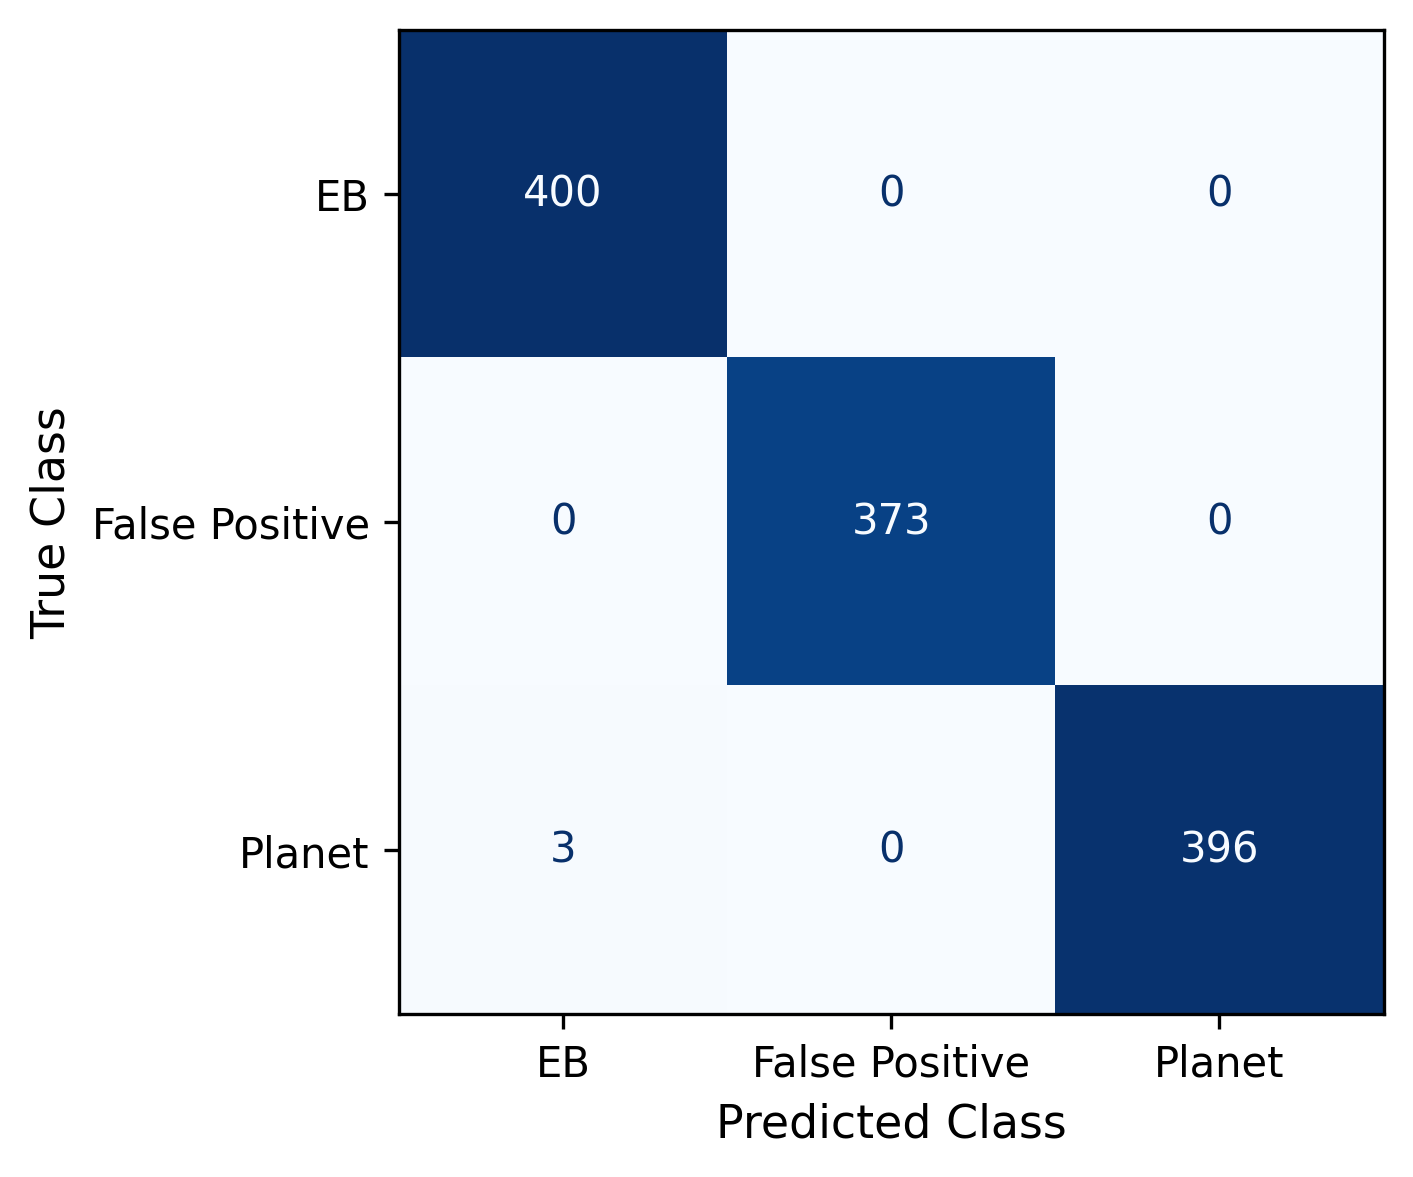

In [ ]:
# ==========================================================
# CONFUSION MATRIX
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# ----------------------------------------------------------
# Correct label mapping
# ----------------------------------------------------------

CLASS_MAPPING = {

    0: "Planet",
    1: "EB",
    2: "False Positive"

}

# ----------------------------------------------------------
# Features used by trained model
# ----------------------------------------------------------

X = df[model.feature_names_in_].astype(float)

# ----------------------------------------------------------
# Model Prediction
# ----------------------------------------------------------

pred = model.predict(X)

pred = pd.Series(pred).map(CLASS_MAPPING)

# ----------------------------------------------------------
# Plot
# ----------------------------------------------------------

fig, ax = plt.subplots(

    figsize=(4.8,4.8),

    dpi=300

)

ConfusionMatrixDisplay.from_predictions(

    df["Label"],

    pred,

    display_labels=[

        "EB",

        "False Positive",

        "Planet"

    ],

    cmap="Blues",

    colorbar=False,

    values_format="d",

    ax=ax

)

ax.set_title("")

ax.set_xlabel(

    "Predicted Class",

    fontsize=11

)

ax.set_ylabel(

    "True Class",

    fontsize=11

)

ax.tick_params(

    labelsize=10

)

plt.tight_layout()

plt.show()

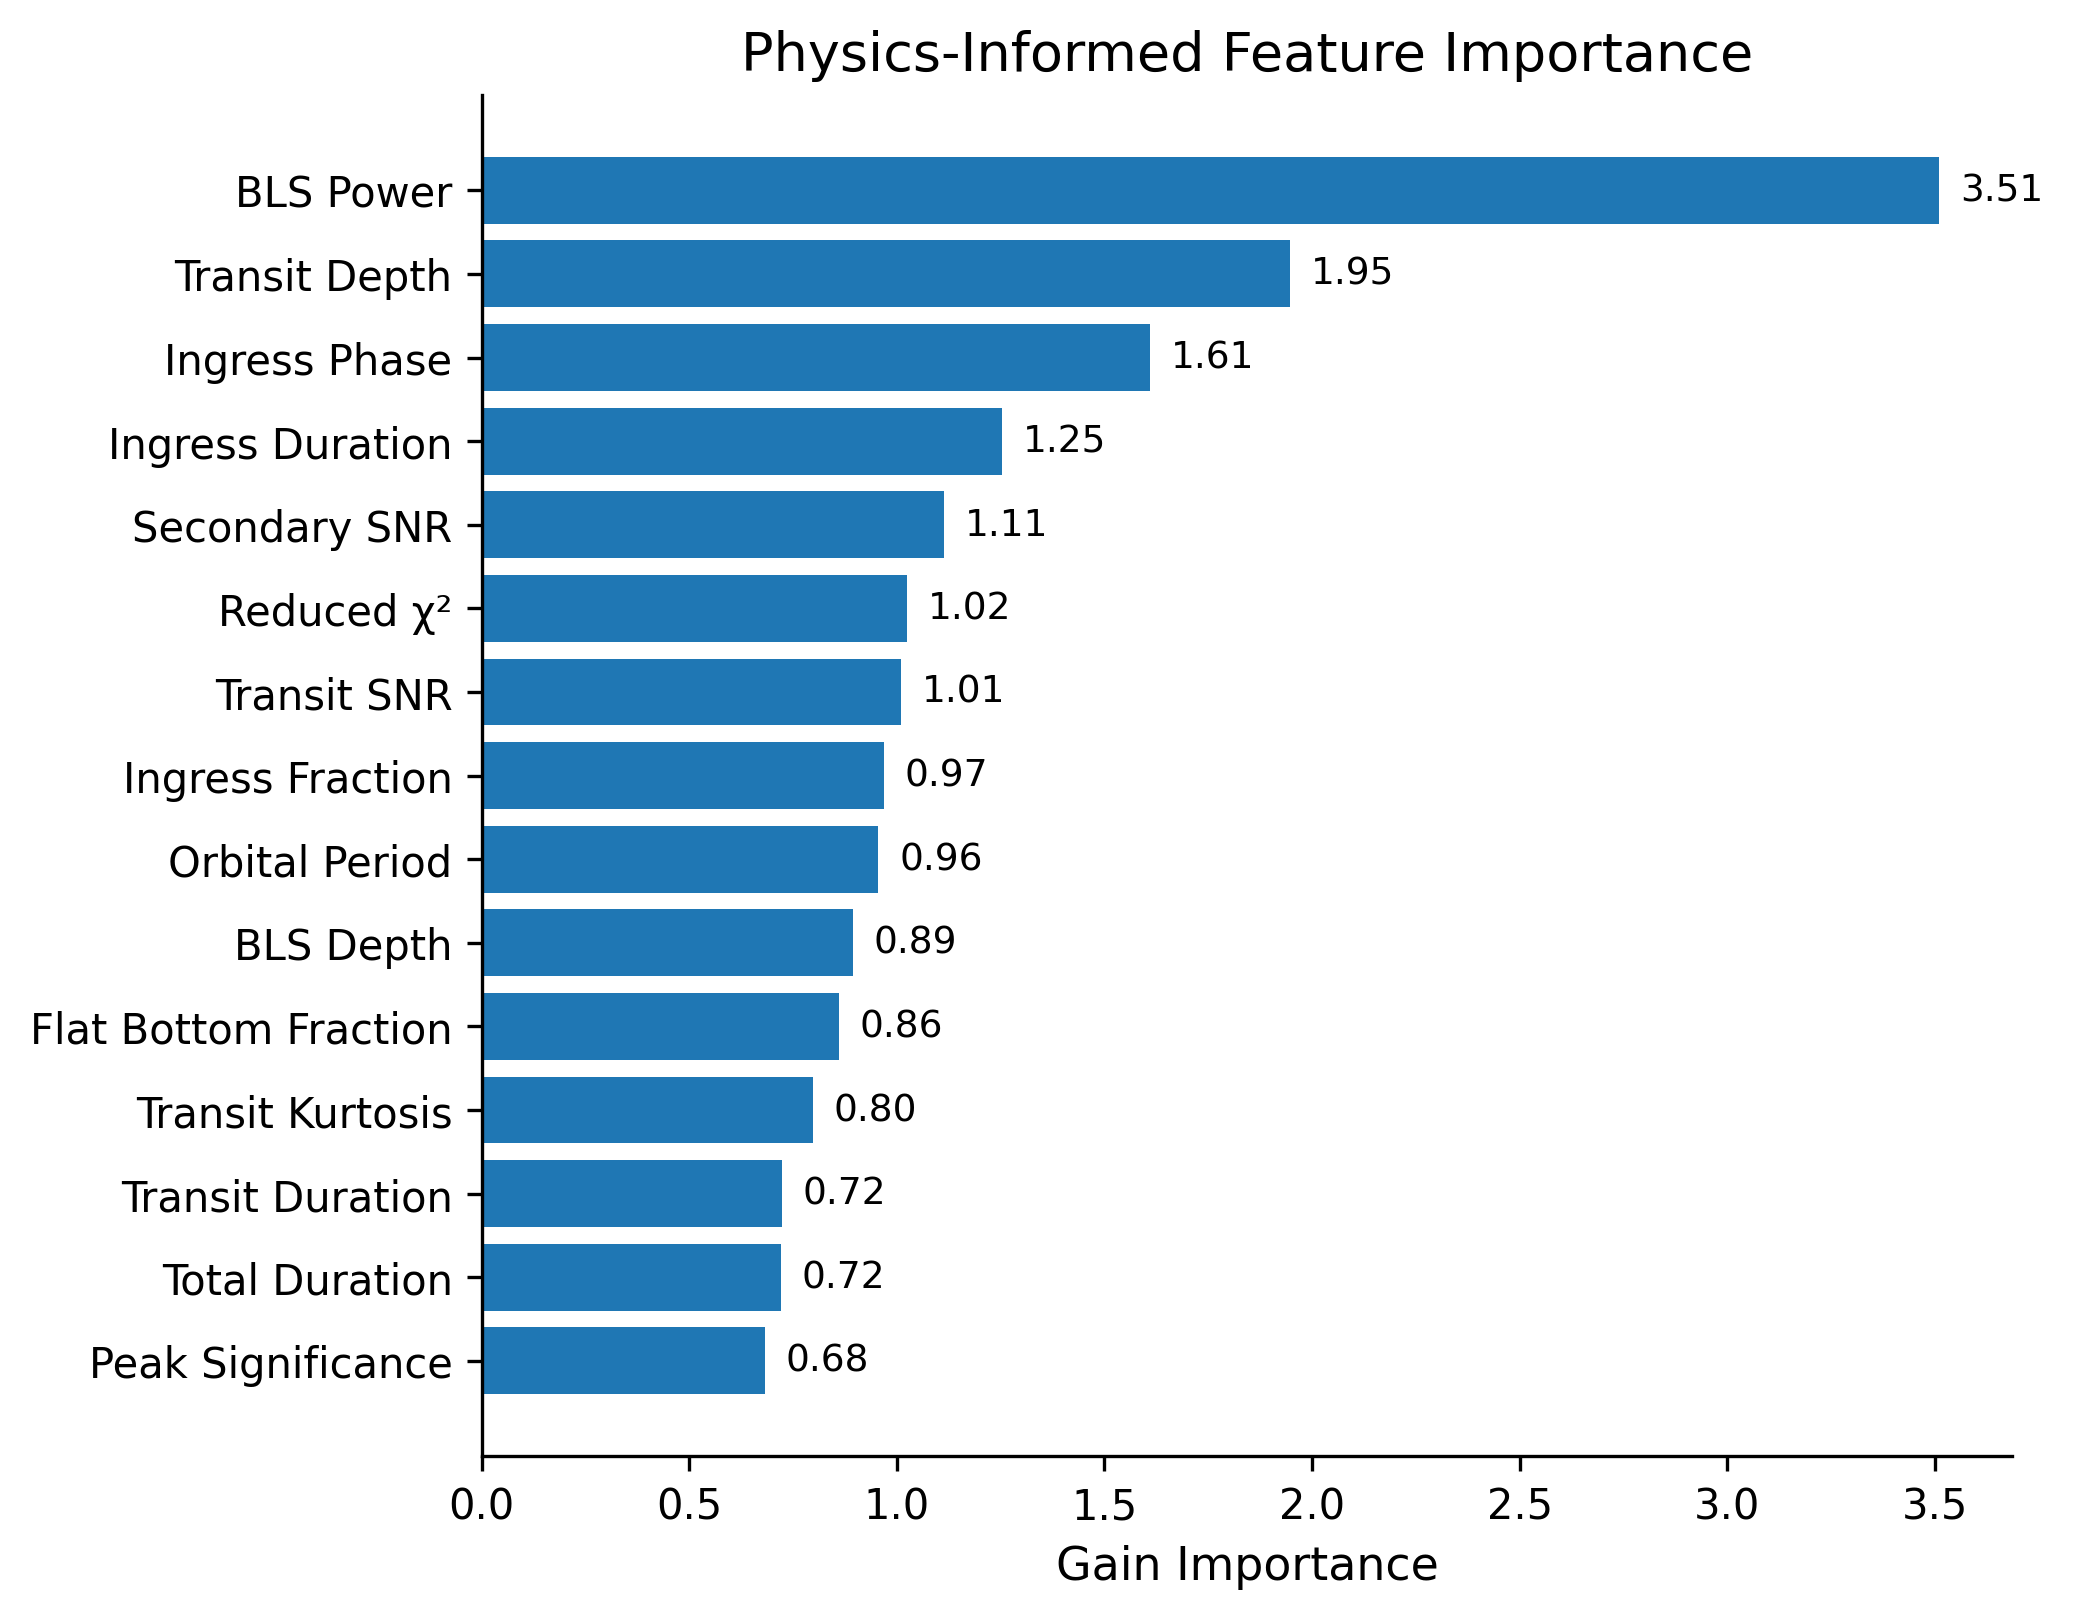

In [ ]:
# ==========================================================
# PUBLICATION-QUALITY FEATURE IMPORTANCE
# ==========================================================

import matplotlib.pyplot as plt
import pandas as pd

# ----------------------------------------------------------
# Extract Feature Importance
# ----------------------------------------------------------

importance = model.get_booster().get_score(
    importance_type="gain"
)

importance = pd.DataFrame({
    "Feature": list(importance.keys()),
    "Importance": list(importance.values())
})

# ----------------------------------------------------------
# Better Feature Names
# ----------------------------------------------------------

feature_map = {

    "bls_power":"BLS Power",
    "depth_ppm":"Transit Depth",
    "ingress_phase":"Ingress Phase",
    "T_in_hours":"Ingress Duration",
    "secondary_snr":"Secondary SNR",
    "red_chi2":"Reduced χ²",
    "transit_snr":"Transit SNR",
    "ingress_fraction":"Ingress Fraction",
    "period_days":"Orbital Period",
    "bls_depth":"BLS Depth",
    "flat_bottom_fraction":"Flat Bottom Fraction",
    "transit_kurtosis":"Transit Kurtosis",
    "duration_days":"Transit Duration",
    "T_tot_hours":"Total Duration",
    "peak_sigma":"Peak Significance",
    "secondary_depth":"Secondary Depth",
    "duty_cycle":"Duty Cycle",
    "oot_rms":"OOT RMS",
    "transit_rms":"Transit RMS",
    "shape_rmse":"Shape RMSE",
    "transit_skewness":"Transit Skewness"

}

importance["Feature"] = importance["Feature"].map(feature_map)

# ----------------------------------------------------------
# Sort
# ----------------------------------------------------------

importance = importance.sort_values(
    "Importance",
    ascending=False
).head(15)

importance = importance.iloc[::-1]

# ----------------------------------------------------------
# Plot
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(7,5.5), dpi=300)

bars = ax.barh(
    importance["Feature"],
    importance["Importance"]
)

# Add values
for bar in bars:

    width = bar.get_width()

    ax.text(

        width + 0.05,

        bar.get_y() + bar.get_height()/2,

        f"{width:.2f}",

        va="center",

        fontsize=9

    )

ax.set_xlabel("Gain Importance", fontsize=11)
ax.set_ylabel("")
ax.set_title("Physics-Informed Feature Importance", fontsize=13)

ax.tick_params(axis="both", labelsize=10)

ax.grid(False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.show()

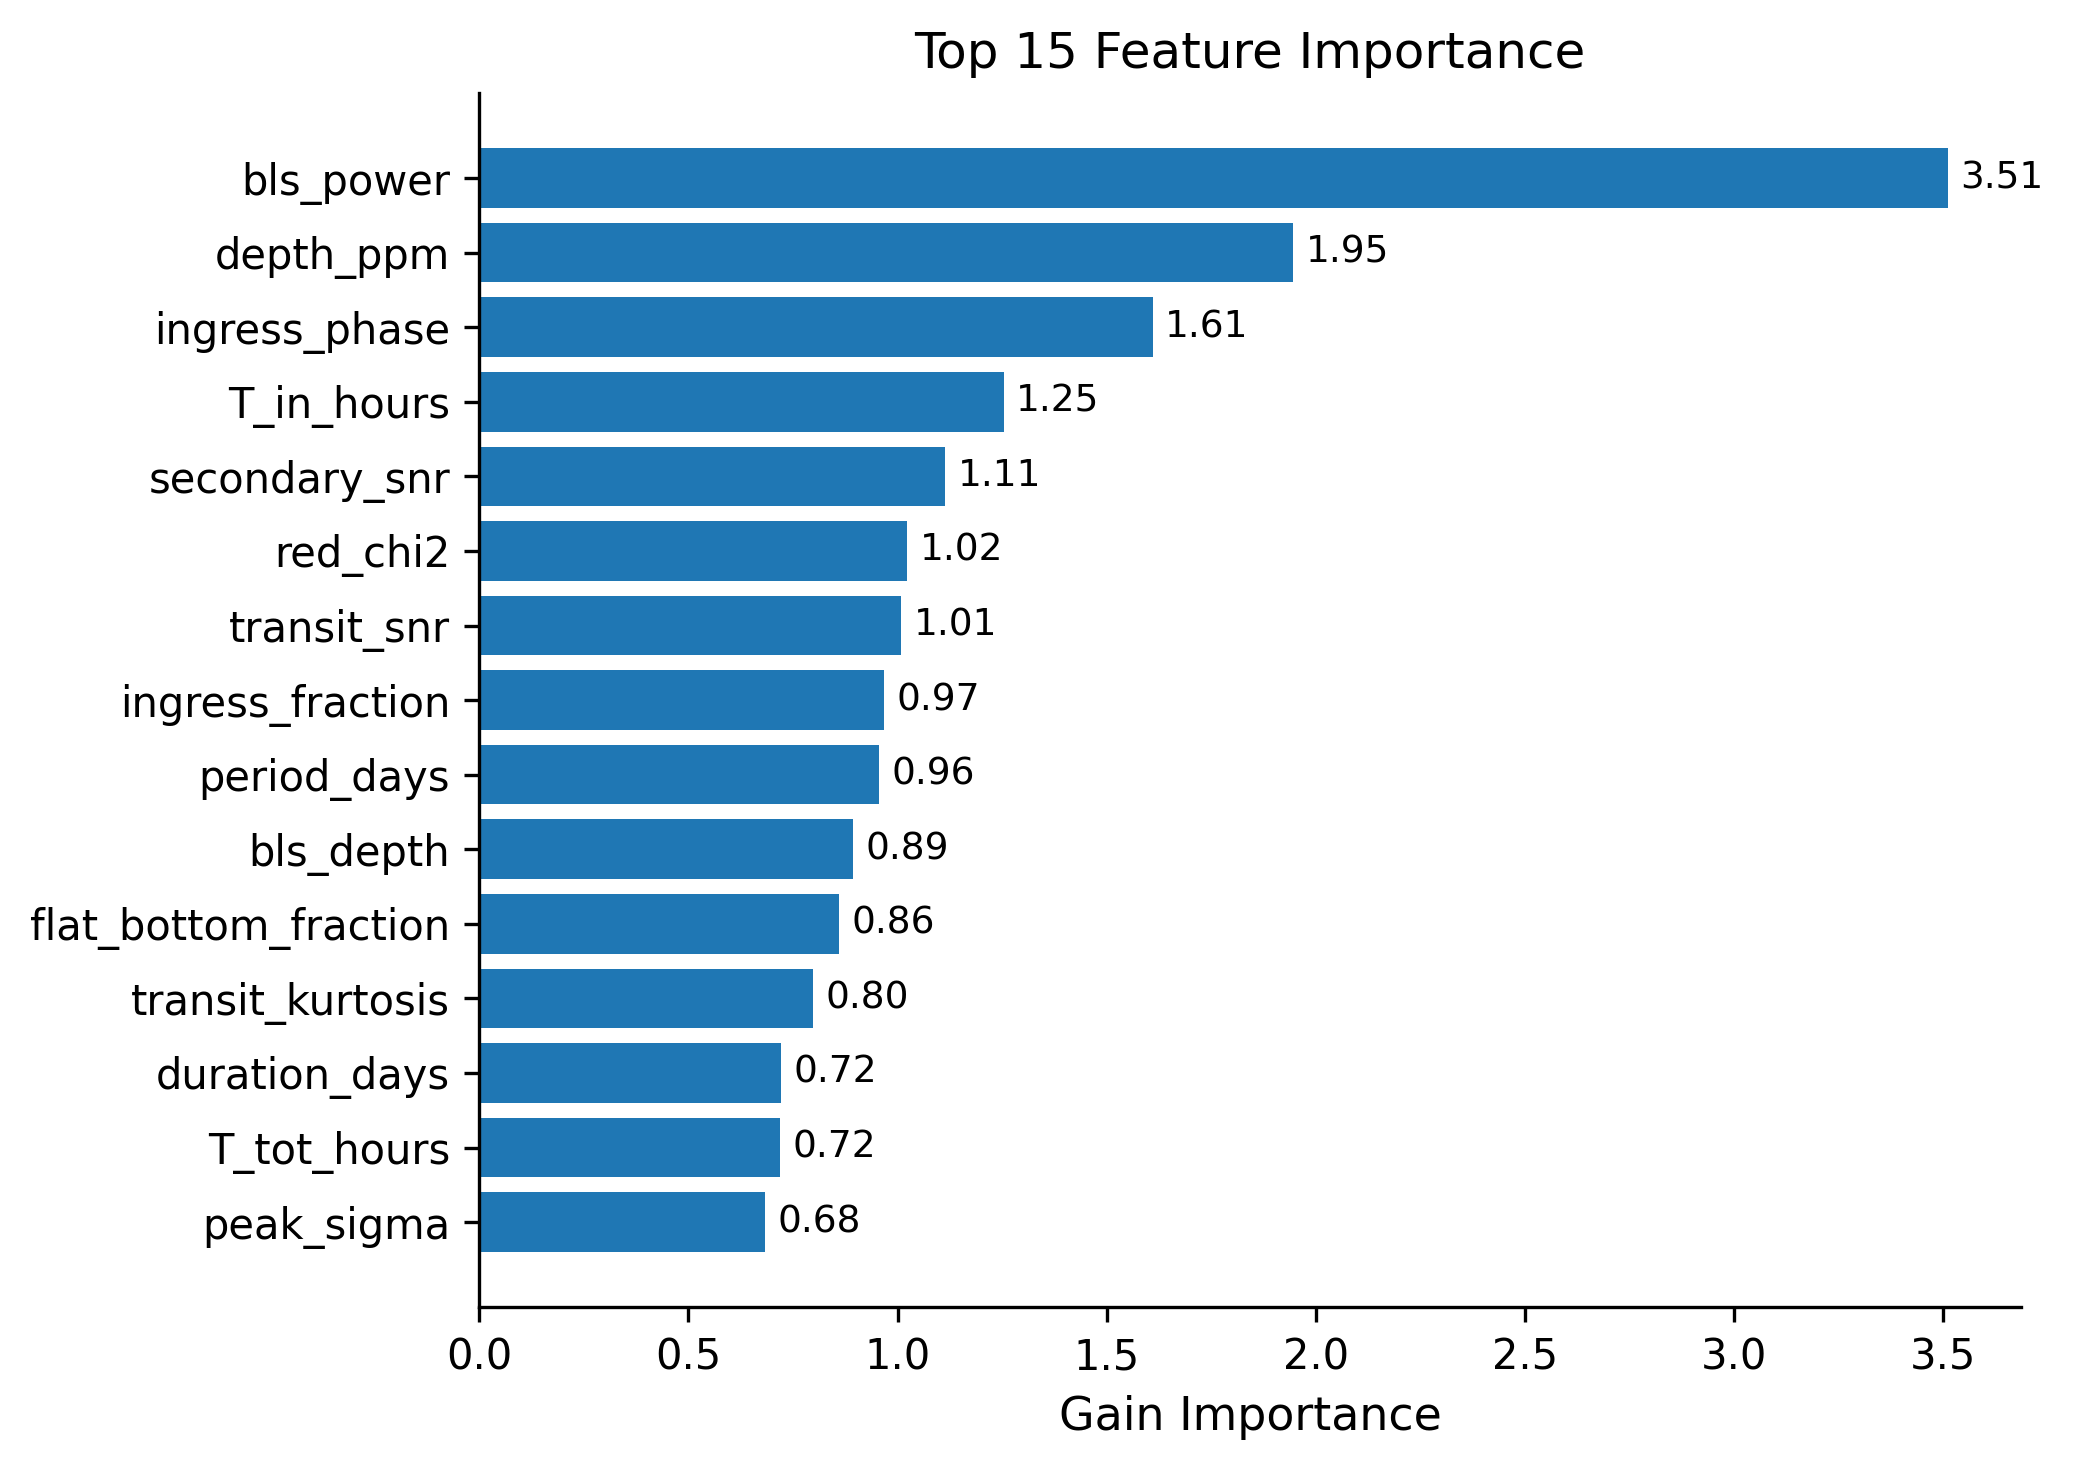

In [ ]:
# ==========================================================
# TOP 15 FEATURE IMPORTANCE
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
importance = model.get_booster().get_score(
    importance_type="gain"
)

# Convert to DataFrame
importance = pd.DataFrame.from_dict(
    importance,
    orient="index",
    columns=["Importance"]
).reset_index()

importance.columns = ["Feature", "Importance"]

# Top 15
importance = (
    importance
    .sort_values("Importance", ascending=False)
    .head(15)
    .sort_values("Importance")
)

# Plot
fig, ax = plt.subplots(figsize=(7,5), dpi=300)

bars = ax.barh(
    importance["Feature"],
    importance["Importance"]
)

# Add values
for bar in bars:

    ax.text(
        bar.get_width() + 0.03,
        bar.get_y() + bar.get_height()/2,
        f"{bar.get_width():.2f}",
        va="center",
        fontsize=9
    )

ax.set_xlabel("Gain Importance", fontsize=11)
ax.set_ylabel("")
ax.set_title("Top 15 Feature Importance", fontsize=12)

ax.tick_params(axis="both", labelsize=10)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()